# Phase 3B Step 8 — Multiple-Group Statistical Comparisons

## Customer Retention Intelligence System

This independent notebook evaluates only three EDA-informed predictor-dependency questions:
tenure across Contract, MonthlyCharges across InternetService, and tenure across
PaymentMethod. Welch's ANOVA is the primary mean-based omnibus method, Kruskal–Wallis is a
complementary rank-distribution method, and Games–Howell provides one coherent post-hoc
procedure after meaningful Welch results.

All omnibus p-values are **exploratory and unadjusted across the three broader hypotheses**.
Games–Howell p-values are adjusted only within their corresponding pairwise family. Results
are neither causal evidence nor feature importance. Only configured `development.parquet`
is loaded.

## 1. Independent setup and leakage-safe loading

The project root is detected from marker files, configuration is loaded through the existing
utility, and the development path is asserted before reading. Prior notebooks are not
executed or required as state.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.8g}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
alpha = 0.05
comparison_specs = {
    "HYP-11": {"numeric": "tenure", "group": "Contract", "business_question": "Does mean tenure differ across contract categories?"},
    "HYP-12": {"numeric": "MonthlyCharges", "group": "InternetService", "business_question": "Do mean monthly charges differ across internet-service categories?"},
    "HYP-13": {"numeric": "tenure", "group": "PaymentMethod", "business_question": "Does mean tenure differ across payment-method categories?"},
}

assert df.shape == (5_634, 21)
assert df[[spec["numeric"] for spec in comparison_specs.values()] + [spec["group"] for spec in comparison_specs.values()]].notna().all().all()
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Configured random state preserved: {random_state}; alpha={alpha}")
print(f"Development SHA-256: {source_sha256_before}")
display(df.head())

Development data: 5,634 rows × 21 columns
Configured random state preserved: 42; alpha=0.05
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.1,"5,475.9",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.35,212.3,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.45,137.1,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.75,"2,453.3",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86,"1,164.05",No


## 2. Exploratory hypotheses and estimands

For each comparison with $k$ groups:

**Primary Welch mean hypothesis**

$$H_0^{mean}:\mu_1=\mu_2=\cdots=\mu_k,$$
$$H_1^{mean}:\text{at least one group mean differs}.$$

**Complementary Kruskal–Wallis rank hypothesis**

$$H_0^{rank}:\text{the groups have the same rank distribution},$$

against at least one distributional departure. Kruskal–Wallis is not generally a test of
median equality when group shapes or spreads differ. Notebook 10 already documented unequal
variances and nonnormal shapes; those diagnostics are reused rather than repeated.

## 3. Welch's ANOVA: primary omnibus comparison

Welch's ANOVA weights each mean by $w_i=n_i/s_i^2$. With weighted mean
$\bar X_w=\sum w_i\bar X_i/\sum w_i$, its numerator measures weighted between-group
variation and its denominator adjusts for variance-estimation uncertainty. The resulting
$F_W$ uses $df_1=k-1$ and a Welch–Satterthwaite-style $df_2$.

Unlike standard ANOVA, Welch does not pool group variances and is appropriate when variances
and sample sizes differ. It still assumes independent observations, meaningful means,
finite variances, and an adequate sampling approximation. SciPy 1.17 supports
`f_oneway(equal_var=False)`; a transparent formula implementation is calculated and checked
against that API.

In [3]:
# ruff: noqa: E501
def welch_anova(groups):
    arrays = [np.asarray(group, float) for group in groups]
    sizes = np.asarray([len(group) for group in arrays], float)
    means = np.asarray([group.mean() for group in arrays])
    variances = np.asarray([group.var(ddof=1) for group in arrays])
    if len(arrays) < 2 or np.any(sizes < 2) or np.any(variances <= 0):
        raise ValueError("Welch ANOVA requires at least two nonconstant groups with n >= 2.")
    k = len(arrays)
    weights = sizes / variances
    weight_sum = weights.sum()
    weighted_mean = np.sum(weights * means) / weight_sum
    adjustment_sum = np.sum((1 - weights / weight_sum) ** 2 / (sizes - 1))
    numerator = np.sum(weights * (means - weighted_mean) ** 2) / (k - 1)
    denominator = 1 + (2 * (k - 2) / (k**2 - 1)) * adjustment_sum
    statistic = numerator / denominator
    df1 = k - 1
    df2 = (k**2 - 1) / (3 * adjustment_sum)
    p_value = stats.f.sf(statistic, df1, df2)
    return statistic, df1, df2, p_value


group_summary_rows = []
welch_rows = []
group_arrays = {}
for hypothesis_id, spec in comparison_specs.items():
    grouped = [(str(category), group[spec["numeric"]].to_numpy(float)) for category, group in df.groupby(spec["group"], observed=True, sort=True)]
    labels = [label for label, _ in grouped]
    arrays = [values for _, values in grouped]
    group_arrays[hypothesis_id] = dict(grouped)
    for label, values in grouped:
        group_summary_rows.append({"hypothesis_id": hypothesis_id, "numeric_variable": spec["numeric"], "grouping_variable": spec["group"], "group": label, "sample_size": len(values), "mean": values.mean(), "variance": values.var(ddof=1), "standard_deviation": values.std(ddof=1)})
    statistic, df1, df2, p_value = welch_anova(arrays)
    scipy_result = stats.f_oneway(*arrays, equal_var=False)
    welch_rows.append({"hypothesis_id": hypothesis_id, "numeric_variable": spec["numeric"], "grouping_variable": spec["group"], "groups": " | ".join(labels), "group_sizes": " | ".join(f"{label}: {len(values)}" for label, values in grouped), "welch_f": statistic, "numerator_df": df1, "denominator_df": df2, "raw_p_value": p_value, "scipy_f_check": scipy_result.statistic, "scipy_p_check": scipy_result.pvalue, "preliminary_decision": "Reject equal-means null (exploratory)" if p_value < alpha else "Do not reject equal-means null", "hypothesis_family": "Multiple-group mean comparisons", "multiplicity_status": "Raw omnibus p-value; broad correction deferred"})

group_summaries = pd.DataFrame(group_summary_rows)
welch_results = pd.DataFrame(welch_rows)
display(group_summaries)
display(welch_results)

,hypothesis_id,numeric_variable,grouping_variable,group,sample_size,mean,variance,standard_deviation
0,HYP-11,tenure,Contract,Month-to-month,3095,18.115347,314.11113,17.72318
1,HYP-11,tenure,Contract,One year,1178,41.52292,375.51222,19.378138
2,HYP-11,tenure,Contract,Two year,1361,56.779574,332.14991,18.22498
3,HYP-12,MonthlyCharges,InternetService,DSL,1934,58.350698,259.05593,16.095214
4,HYP-12,MonthlyCharges,InternetService,Fiber optic,2493,91.517228,160.45369,12.667032
5,HYP-12,MonthlyCharges,InternetService,No,1207,21.036785,4.632261,2.1522688
6,HYP-13,tenure,PaymentMethod,Bank transfer (automatic),1246,43.211878,538.39041,23.203241
7,HYP-13,tenure,PaymentMethod,Credit card (automatic),1215,43.312757,542.76372,23.29729
8,HYP-13,tenure,PaymentMethod,Electronic check,1877,25.496537,508.85353,22.557782
9,HYP-13,tenure,PaymentMethod,Mailed check,1296,21.554012,454.05113,21.308476


,hypothesis_id,numeric_variable,grouping_variable,groups,group_sizes,welch_f,numerator_df,denominator_df,raw_p_value,scipy_f_check,scipy_p_check,preliminary_decision,hypothesis_family,multiplicity_status
0,HYP-11,tenure,Contract,Month-to-month | One year | Two year,Month-to-month: 3095 | One year: 1178 | Two ye...,"2,348.5449",2,"2,541.6904",0,"2,348.5449",0,Reject equal-means null (exploratory),Multiple-group mean comparisons,Raw omnibus p-value; broad correction deferred
1,HYP-12,MonthlyCharges,InternetService,DSL | Fiber optic | No,DSL: 1934 | Fiber optic: 2493 | No: 1207,"40,452.018",2,"3,121.0253",0,"40,452.018",0,Reject equal-means null (exploratory),Multiple-group mean comparisons,Raw omnibus p-value; broad correction deferred
2,HYP-13,tenure,PaymentMethod,Bank transfer (automatic) | Credit card (autom...,Bank transfer (automatic): 1246 | Credit card ...,347.94316,3,"2,955.8805",1.7022702e-193,347.94316,1.7022702e-193,Reject equal-means null (exploratory),Multiple-group mean comparisons,Raw omnibus p-value; broad correction deferred


## 4. Kruskal–Wallis: complementary rank-distribution comparison

Kruskal–Wallis pools observations, assigns average ranks to ties, and compares group rank
sums. SciPy applies the tie correction to $H$, which is referenced to $\chi^2_{k-1}$ for
adequate samples. This notebook reports rank-based epsilon squared using

$$\epsilon_R^2=\max\left(0,\frac{H-k+1}{N-k}\right).$$

It is an omnibus rank-distribution effect convention, not variance explained in the linear-
model sense. Mean and rank conclusions remain separate because they answer different
questions.

In [4]:
# ruff: noqa: E501
kruskal_rows = []
for hypothesis_id, spec in comparison_specs.items():
    mapping = group_arrays[hypothesis_id]
    arrays = list(mapping.values())
    result = stats.kruskal(*arrays, nan_policy="raise")
    k = len(arrays); total_n = sum(len(values) for values in arrays)
    epsilon_squared = max(0.0, (result.statistic - k + 1) / (total_n - k))
    combined = np.concatenate(arrays)
    tie_present = np.unique(combined).size < len(combined)
    kruskal_rows.append({"hypothesis_id": hypothesis_id, "numeric_variable": spec["numeric"], "grouping_variable": spec["group"], "method": "Kruskal–Wallis (tie-corrected)", "h_statistic": result.statistic, "degrees_of_freedom": k - 1, "raw_p_value": result.pvalue, "rank_epsilon_squared": epsilon_squared, "ties_present_and_corrected": tie_present, "preliminary_decision": "Reject equal-rank-distributions null (exploratory)" if result.pvalue < alpha else "Do not reject rank-distributions null", "hypothesis_family": "Multiple-group rank comparisons", "multiplicity_status": "Raw omnibus p-value; broad correction deferred"})
kruskal_results = pd.DataFrame(kruskal_rows)
display(kruskal_results)

,hypothesis_id,numeric_variable,grouping_variable,method,h_statistic,degrees_of_freedom,raw_p_value,rank_epsilon_squared,ties_present_and_corrected,preliminary_decision,hypothesis_family,multiplicity_status
0,HYP-11,tenure,Contract,Kruskal–Wallis (tie-corrected),"2,479.0843",2,0,0.43990131,True,Reject equal-rank-distributions null (explorat...,Multiple-group rank comparisons,Raw omnibus p-value; broad correction deferred
1,HYP-12,MonthlyCharges,InternetService,Kruskal–Wallis (tie-corrected),"4,415.5231",2,0,0.78379028,True,Reject equal-rank-distributions null (explorat...,Multiple-group rank comparisons,Raw omnibus p-value; broad correction deferred
2,HYP-13,tenure,PaymentMethod,Kruskal–Wallis (tie-corrected),911.46025,3,2.8920526e-197,0.16136061,True,Reject equal-rank-distributions null (explorat...,Multiple-group rank comparisons,Raw omnibus p-value; broad correction deferred


## 5. Games–Howell post-hoc comparisons

A significant omnibus result says at least one mean differs but does not identify the pairs.
Games–Howell is aligned with Welch because each pair uses its own unequal-variance standard
error and Satterthwaite degrees of freedom. For pair $i-j$,

$$SE_{ij}=\sqrt{s_i^2/n_i+s_j^2/n_j},\qquad
q_{ij}=\frac{|\bar X_i-\bar X_j|}{\sqrt{(s_i^2/n_i+s_j^2/n_j)/2}}.$$

The studentized-range distribution with all $k$ family groups supplies the within-family
adjusted p-value and simultaneous confidence interval. This adjustment covers pairwise
comparisons inside HYP-11, HYP-12, or HYP-13 only; it is distinct from Step 10's broader
hypothesis-family correction. Tukey HSD is not used because it relies on pooled-variance
logic that Notebook 10 found unsuitable.

In [5]:
# ruff: noqa: E501
def games_howell(mapping, confidence=0.95):
    labels = list(mapping)
    k = len(labels)
    rows = []
    for left, right in itertools.combinations(labels, 2):
        a = np.asarray(mapping[left], float); b = np.asarray(mapping[right], float)
        na, nb = len(a), len(b); ma, mb = a.mean(), b.mean(); va, vb = a.var(ddof=1), b.var(ddof=1)
        difference = ma - mb
        variance_term = va / na + vb / nb
        se_difference = np.sqrt(variance_term)
        pair_df = variance_term**2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
        q_statistic = abs(difference) / np.sqrt(variance_term / 2)
        adjusted_p = stats.studentized_range.sf(q_statistic, k, pair_df)
        q_critical = stats.studentized_range.ppf(confidence, k, pair_df)
        margin = q_critical * np.sqrt(variance_term / 2)
        rows.append({"group_1": left, "group_2": right, "comparison_direction": f"{left} − {right}", "group_1_n": na, "group_2_n": nb, "group_1_mean": ma, "group_2_mean": mb, "mean_difference": difference, "standard_error_difference": se_difference, "satterthwaite_df": pair_df, "studentized_range_q": q_statistic, "ci_lower": difference - margin, "ci_upper": difference + margin, "games_howell_adjusted_p": adjusted_p, "within_family_significant": adjusted_p < alpha})
    return pd.DataFrame(rows)


posthoc_tables = {}
posthoc_rows = []
for hypothesis_id, spec in comparison_specs.items():
    if welch_results.loc[welch_results["hypothesis_id"].eq(hypothesis_id), "raw_p_value"].iloc[0] < alpha:
        table = games_howell(group_arrays[hypothesis_id])
        table.insert(0, "hypothesis_id", hypothesis_id)
        table.insert(1, "numeric_variable", spec["numeric"])
        table.insert(2, "grouping_variable", spec["group"])
        table["adjustment_scope"] = f"Games–Howell across all {len(group_arrays[hypothesis_id])} {spec['group']} groups"
        posthoc_tables[hypothesis_id] = table
        posthoc_rows.extend(table.to_dict("records"))
games_howell_results = pd.DataFrame(posthoc_rows)
display(games_howell_results)

,hypothesis_id,numeric_variable,grouping_variable,group_1,group_2,comparison_direction,group_1_n,group_2_n,group_1_mean,group_2_mean,mean_difference,standard_error_difference,satterthwaite_df,studentized_range_q,ci_lower,ci_upper,games_howell_adjusted_p,within_family_significant,adjustment_scope
0,HYP-11,tenure,Contract,Month-to-month,One year,Month-to-month − One year,3095,1178,18.115347,41.52292,-23.407573,0.64827529,"1,969.8126",51.063657,-24.928088,-21.887058,0,True,Games–Howell across all 3 Contract groups
1,HYP-11,tenure,Contract,Month-to-month,Two year,Month-to-month − Two year,3095,1361,18.115347,56.779574,-38.664227,0.58782505,"2,533.7282",93.019979,-40.042724,-37.285729,6.3882233e-13,True,Games–Howell across all 3 Contract groups
2,HYP-11,tenure,Contract,One year,Two year,One year − Two year,1178,1361,41.52292,56.779574,-15.256654,0.75021291,"2,434.268",28.760058,-17.016006,-13.497301,0,True,Games–Howell across all 3 Contract groups
3,HYP-12,MonthlyCharges,InternetService,DSL,Fiber optic,DSL − Fiber optic,1934,2493,58.350698,91.517228,-33.16653,0.44532005,"3,593.3605",105.32775,-34.210661,-32.1224,4.3076653e-14,True,Games–Howell across all 3 InternetService groups
4,HYP-12,MonthlyCharges,InternetService,DSL,No,DSL − No,1934,1207,58.350698,21.036785,37.313913,0.37119548,"2,042.6662",142.16186,36.443306,38.18452,7.9325435e-13,True,Games–Howell across all 3 InternetService groups
5,HYP-12,MonthlyCharges,InternetService,Fiber optic,No,Fiber optic − No,2493,1207,91.517228,21.036785,70.480443,0.26115038,"2,777.6444",381.67434,69.868056,71.09283,3.425038e-13,True,Games–Howell across all 3 InternetService groups
6,HYP-13,tenure,PaymentMethod,Bank transfer (automatic),Credit card (automatic),Bank transfer (automatic) − Credit card (autom...,1246,1215,43.211878,43.312757,-0.10087919,0.93745088,"2,456.898",0.15218368,-2.5108691,2.3091107,0.99955423,False,Games–Howell across all 4 PaymentMethod groups
7,HYP-13,tenure,PaymentMethod,Bank transfer (automatic),Electronic check,Bank transfer (automatic) − Electronic check,1246,1877,43.211878,25.496537,17.715341,0.83856688,"2,614.3568",29.8763,15.55965,19.871032,0,True,Games–Howell across all 4 PaymentMethod groups
8,HYP-13,tenure,PaymentMethod,Bank transfer (automatic),Mailed check,Bank transfer (automatic) − Mailed check,1246,1296,43.211878,21.554012,21.657866,0.88455816,"2,501.4229",34.626154,19.38388,23.931852,1.513345e-12,True,Games–Howell across all 4 PaymentMethod groups
9,HYP-13,tenure,PaymentMethod,Credit card (automatic),Electronic check,Credit card (automatic) − Electronic check,1215,1877,43.312757,25.496537,17.81622,0.84724169,"2,531.299",29.738787,15.638183,19.994257,0,True,Games–Howell across all 4 PaymentMethod groups


## 6. Consolidated exploratory results

Primary and complementary omnibus hypotheses are recorded separately for Step 10. Small
p-values are retained numerically and displayed in scientific notation; floating-point
underflow, if encountered, is labeled rather than presented as mathematical zero.

In [6]:
# ruff: noqa: E501
def format_p(value):
    if value == 0:
        return f"underflow (<{np.nextafter(0, 1):.2e})"
    return f"{value:.6e}"


business_interpretations = {
    "HYP-11": "Contract categories have materially different tenure profiles; commitment and lifecycle are strongly dependent, creating confounding in marginal churn comparisons.",
    "HYP-12": "Internet-service categories occupy very different monthly-price bands, reflecting product architecture and creating predictor dependence.",
    "HYP-13": "Payment methods have different tenure profiles; payment behaviour is entangled with lifecycle and contract composition.",
}
consolidated_rows = []
for hypothesis_id, spec in comparison_specs.items():
    welch = welch_results.loc[welch_results["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    kruskal = kruskal_results.loc[kruskal_results["hypothesis_id"].eq(hypothesis_id)].iloc[0]
    significant_pairs = games_howell_results[(games_howell_results["hypothesis_id"].eq(hypothesis_id)) & games_howell_results["within_family_significant"]]
    pair_summary = "; ".join(f"{row.comparison_direction}: Δ={row.mean_difference:+.2f}, CI [{row.ci_lower:.2f}, {row.ci_upper:.2f}], p_adj={format_p(row.games_howell_adjusted_p)}" for _, row in significant_pairs.iterrows())
    consolidated_rows.extend([
        {"hypothesis_id": hypothesis_id, "variables_compared": f"{spec['numeric']} across {spec['group']}", "method_role": "Primary mean omnibus", "statistical_method": "Welch's ANOVA", "group_sizes": welch["group_sizes"], "test_statistic": welch["welch_f"], "numerator_df": welch["numerator_df"], "denominator_df": welch["denominator_df"], "raw_omnibus_p": welch["raw_p_value"], "raw_p_display": format_p(welch["raw_p_value"]), "effect_size": np.nan, "effect_size_name": "Not added; consolidated effect-size analysis deferred", "posthoc_findings": pair_summary, "business_interpretation": business_interpretations[hypothesis_id], "hypothesis_family": welch["hypothesis_family"], "multiplicity_status": welch["multiplicity_status"]},
        {"hypothesis_id": hypothesis_id, "variables_compared": f"{spec['numeric']} across {spec['group']}", "method_role": "Complementary rank omnibus", "statistical_method": "Kruskal–Wallis", "group_sizes": welch["group_sizes"], "test_statistic": kruskal["h_statistic"], "numerator_df": kruskal["degrees_of_freedom"], "denominator_df": np.nan, "raw_omnibus_p": kruskal["raw_p_value"], "raw_p_display": format_p(kruskal["raw_p_value"]), "effect_size": kruskal["rank_epsilon_squared"], "effect_size_name": "Rank epsilon-squared", "posthoc_findings": "No rank post-hoc added; Games–Howell answers the primary mean question", "business_interpretation": business_interpretations[hypothesis_id], "hypothesis_family": kruskal["hypothesis_family"], "multiplicity_status": kruskal["multiplicity_status"]},
    ])
consolidated_results = pd.DataFrame(consolidated_rows)
display(consolidated_results)

display(Markdown(
    "### Actual omnibus findings\n\n"
    + "\n".join(
        f"- **{row.hypothesis_id} — {row.numeric_variable} across {row.grouping_variable}:** Welch F({row.numerator_df:.0f}, {row.denominator_df:.1f})={row.welch_f:.3f}, raw p={format_p(row.raw_p_value)}; Kruskal H({int(kruskal_results.loc[kruskal_results['hypothesis_id'].eq(row.hypothesis_id), 'degrees_of_freedom'].iloc[0])})={kruskal_results.loc[kruskal_results['hypothesis_id'].eq(row.hypothesis_id), 'h_statistic'].iloc[0]:.3f}, rank ε²={kruskal_results.loc[kruskal_results['hypothesis_id'].eq(row.hypothesis_id), 'rank_epsilon_squared'].iloc[0]:.3f}."
        for _, row in welch_results.iterrows()
    )
))

,hypothesis_id,variables_compared,method_role,statistical_method,group_sizes,test_statistic,numerator_df,denominator_df,raw_omnibus_p,raw_p_display,effect_size,effect_size_name,posthoc_findings,business_interpretation,hypothesis_family,multiplicity_status
0,HYP-11,tenure across Contract,Primary mean omnibus,Welch's ANOVA,Month-to-month: 3095 | One year: 1178 | Two ye...,"2,348.5449",2,"2,541.6904",0,underflow (<4.94e-324),NaN,Not added; consolidated effect-size analysis d...,"Month-to-month − One year: Δ=-23.41, CI [-24.9...",Contract categories have materially different ...,Multiple-group mean comparisons,Raw omnibus p-value; broad correction deferred
1,HYP-11,tenure across Contract,Complementary rank omnibus,Kruskal–Wallis,Month-to-month: 3095 | One year: 1178 | Two ye...,"2,479.0843",2,NaN,0,underflow (<4.94e-324),0.43990131,Rank epsilon-squared,No rank post-hoc added; Games–Howell answers t...,Contract categories have materially different ...,Multiple-group rank comparisons,Raw omnibus p-value; broad correction deferred
2,HYP-12,MonthlyCharges across InternetService,Primary mean omnibus,Welch's ANOVA,DSL: 1934 | Fiber optic: 2493 | No: 1207,"40,452.018",2,"3,121.0253",0,underflow (<4.94e-324),NaN,Not added; consolidated effect-size analysis d...,"DSL − Fiber optic: Δ=-33.17, CI [-34.21, -32.1...",Internet-service categories occupy very differ...,Multiple-group mean comparisons,Raw omnibus p-value; broad correction deferred
3,HYP-12,MonthlyCharges across InternetService,Complementary rank omnibus,Kruskal–Wallis,DSL: 1934 | Fiber optic: 2493 | No: 1207,"4,415.5231",2,NaN,0,underflow (<4.94e-324),0.78379028,Rank epsilon-squared,No rank post-hoc added; Games–Howell answers t...,Internet-service categories occupy very differ...,Multiple-group rank comparisons,Raw omnibus p-value; broad correction deferred
4,HYP-13,tenure across PaymentMethod,Primary mean omnibus,Welch's ANOVA,Bank transfer (automatic): 1246 | Credit card ...,347.94316,3,"2,955.8805",1.7022702e-193,1.702270e-193,NaN,Not added; consolidated effect-size analysis d...,Bank transfer (automatic) − Electronic check: ...,Payment methods have different tenure profiles...,Multiple-group mean comparisons,Raw omnibus p-value; broad correction deferred
5,HYP-13,tenure across PaymentMethod,Complementary rank omnibus,Kruskal–Wallis,Bank transfer (automatic): 1246 | Credit card ...,911.46025,3,NaN,2.8920526e-197,2.892053e-197,0.16136061,Rank epsilon-squared,No rank post-hoc added; Games–Howell answers t...,Payment methods have different tenure profiles...,Multiple-group rank comparisons,Raw omnibus p-value; broad correction deferred


### Actual omnibus findings

- **HYP-11 — tenure across Contract:** Welch F(2, 2541.7)=2348.545, raw p=underflow (<4.94e-324); Kruskal H(2)=2479.084, rank ε²=0.440.
- **HYP-12 — MonthlyCharges across InternetService:** Welch F(2, 3121.0)=40452.018, raw p=underflow (<4.94e-324); Kruskal H(2)=4415.523, rank ε²=0.784.
- **HYP-13 — tenure across PaymentMethod:** Welch F(3, 2955.9)=347.943, raw p=1.702270e-193; Kruskal H(3)=911.460, rank ε²=0.161.

## 7. Essential visualization: Games–Howell mean differences

Each panel uses the original variable's units and shows simultaneous within-family 95%
Games–Howell intervals. The vertical zero line denotes no mean difference. Previous
distribution, box, and diagnostic plots are not repeated.

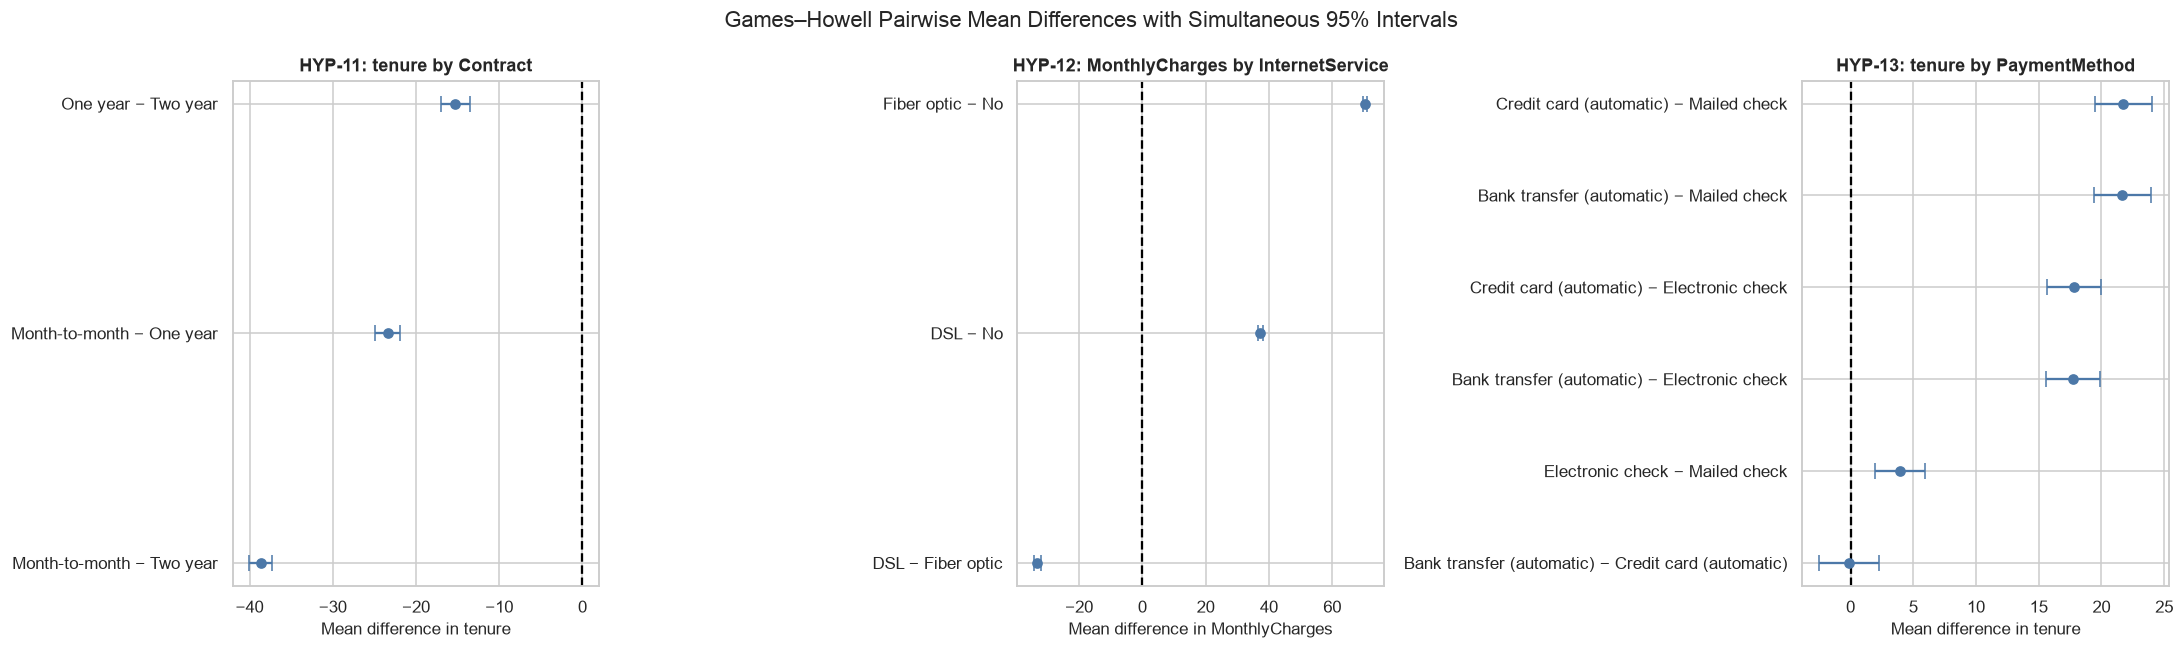

In [7]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for axis, hypothesis_id in zip(axes, comparison_specs, strict=True):
    view = games_howell_results[games_howell_results["hypothesis_id"].eq(hypothesis_id)].sort_values("mean_difference")
    axis.errorbar(view["mean_difference"], view["comparison_direction"], xerr=[view["mean_difference"] - view["ci_lower"], view["ci_upper"] - view["mean_difference"]], fmt="o", capsize=5, color="#4C78A8")
    axis.axvline(0, color="black", linestyle="--")
    spec = comparison_specs[hypothesis_id]
    axis.set(title=f"{hypothesis_id}: {spec['numeric']} by {spec['group']}", xlabel=f"Mean difference in {spec['numeric']}", ylabel="")
fig.suptitle("Games–Howell Pairwise Mean Differences with Simultaneous 95% Intervals")
fig.tight_layout()
plt.show()

## 8. Business and modelling implications

- **Contract and tenure:** commitment categories encode very different lifecycle profiles.
  Contract–churn associations can therefore be confounded by tenure, and model explanations
  must distinguish marginal from conditional effects.
- **Internet service and price:** service type strongly structures MonthlyCharges. Encoding
  both can produce correlated signals; that is product semantics, not a reason for automatic
  deletion.
- **Payment method and tenure:** automatic-payment groups are more established on average,
  while electronic/mailed-check groups are earlier in lifecycle. Payment–churn patterns may
  partly reflect this composition.

These results motivate careful encoding, conditional analysis, interaction review, and later
multicollinearity diagnostics for appropriate models. They are not causal effects or formal
feature importance, and no feature engineering or selection occurs here.

## 9. Interview questions with speakable answers

### Q1. Standard ANOVA versus Welch's ANOVA?

**Answer:** Both test equality of group means. Standard ANOVA pools a common within-group
variance. Welch weights groups by their own variance and adjusts denominator degrees of
freedom, making it safer with unequal variances and unequal sizes. Notebook 10 found those
conditions here, so Welch is the primary omnibus test.

### Q2. ANOVA versus Kruskal–Wallis?

**Answer:** ANOVA targets group means; Kruskal–Wallis targets rank distributions. Kruskal is
not automatically a median test when shapes or spreads differ. I select based on the
estimand, using Kruskal here only as a complementary rank perspective.

### Q3. Why are post-hoc comparisons necessary?

**Answer:** A significant omnibus test says at least one group differs but not which pair.
Post-hoc procedures estimate pairwise differences while controlling the extra false-positive
opportunity created by inspecting all pairs within that family.

### Q4. Why Games–Howell instead of Tukey HSD?

**Answer:** Tukey HSD uses pooled-variance logic. Games–Howell allows each pair to have
unequal variances and uses Satterthwaite degrees of freedom with the studentized-range
distribution, matching the assumptions behind Welch's ANOVA.

## 10. Assumptions and limitations

1. Customer observations and groups are treated as independent; hidden clustering or time
   structure is unavailable.
2. Sampling mechanism and population representativeness are unknown.
3. Welch targets means; Kruskal targets ranks. Their rejections are not interchangeable.
4. Games–Howell adjustment is only within each comparison family; broader correction is
   deferred to Step 10.
5. Epsilon-squared is a rank-effect convention and not linear variance explained.
6. Predictor relationships are marginal and can reflect structural product definitions,
   selection, and confounding.
7. No repeated diagnostics, simulations, causal claims, feature selection, engineering,
   balancing, modelling, DVC changes, or multiple-group rank post-hoc method is added.

## 11. Numerical, integrity, and leakage verification

The final cell checks the formula Welch statistic against SciPy, Games–Howell identities and
interval ordering, rank-effect bounds, all twelve prior notebook hashes, source checksum,
and development-only loading.

In [8]:
# ruff: noqa: E501
assert np.allclose(welch_results["welch_f"], welch_results["scipy_f_check"], rtol=1e-12)
assert np.allclose(welch_results["raw_p_value"], welch_results["scipy_p_check"], rtol=1e-10)
assert welch_results["raw_p_value"].between(0, 1).all()
assert kruskal_results["raw_p_value"].between(0, 1).all()
assert kruskal_results["rank_epsilon_squared"].between(0, 1).all()
assert kruskal_results["ties_present_and_corrected"].all()
assert games_howell_results["games_howell_adjusted_p"].between(0, 1).all()
assert (games_howell_results["ci_lower"] <= games_howell_results["mean_difference"]).all()
assert (games_howell_results["mean_difference"] <= games_howell_results["ci_upper"]).all()
assert len(games_howell_results) == 12
assert games_howell_results.groupby("hypothesis_id")["within_family_significant"].any().all()

expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
    "09_confidence_interval_analysis.ipynb": "50bf2497adec4d4e5d09502b0849420c9e53d5383615152f51fbc71629fb61c3",
    "10_distribution_diagnostics.ipynb": "38341766a6a26f1c7ba03c521500d15eef0038efd9e01d7b6bf7468de0dd1b58",
    "11_numerical_hypothesis_testing.ipynb": "fe98c6d2591d9f87dd256ae9a37a32004e194297f8dc01ce44abc6bff6501662",
    "12_categorical_hypothesis_testing.ipynb": "4d6cd50439617c88f1f0452961c56d0069877fa3352436bccc2aa35fa3f53389",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42 and alpha == 0.05

print("All Welch, Kruskal, Games–Howell, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All Welch, Kruskal, Games–Howell, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
09_confidence_interval_analysis.ipynb,50bf2497adec4d4e5d09502b0849420c9e53d538361515...,50bf2497adec4d4e5d09502b0849420c9e53d538361515...
10_distribution_diagnostics.ipynb,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...
